# Machine Learning — régimes de marché

Classificateur expérimental de contexte de marché, pour paper trading uniquement. Aucun ordre réel n'est déclenché.

Deux évaluations :

1. **split fixe** train / validation / test (référence historique) ;
2. **walk-forward** à fenêtre expansive, réentraînement mensuel, purge stricte des cibles, puis comparaison financière **avec frais** contre Buy & Hold, Momentum et Momentum + VT sur les mêmes mois.

In [1]:
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_prices
from src.market_regime import FEATURE_COLUMNS, generate_regime_report, run_regime_study
from src.monthly_pipeline import load_config, run_monthly_pipeline

data_path = PROJECT_ROOT / 'data' / 'processed' / 'universe_prices.csv'
if not data_path.exists():
    data_path = PROJECT_ROOT / 'data' / 'processed' / 'momentum_universe.csv'
prices_daily = load_prices(data_path)
config = load_config(PROJECT_ROOT / 'config' / 'strategy_params.yaml')
print(f'Données locales : {data_path}')
print(f'Période quotidienne : {prices_daily.index.min().date()} → {prices_daily.index.max().date()}')

Données locales : C:\Users\degar\OneDrive - De Vinci Higher Education (DVHE)\Perso\Projet Investissement\personal-quant-lab\data\processed\universe_prices.csv
Période quotidienne : 2015-01-02 → 2026-09-23


In [2]:
# Univers et mois complets identiques au rapport mensuel (anti-look-ahead inclus).
pipeline = run_monthly_pipeline(prices_daily, config)
monthly_prices = pipeline.monthly_prices
print('Univers retenu :', list(monthly_prices.columns))
study = run_regime_study(prices_daily, monthly_prices, config)
evaluation, walk_forward = study['evaluation'], study['walk_forward']
pd.Series({k: evaluation['dataset'][k] for k in ('start', 'end', 'n_observations', 'train_size', 'validation_size', 'test_size', 'risk_off', 'risk_on')})

Univers retenu : ['CW8.PA', 'ESE.PA', 'PAEEM.PA', 'PUST.PA', 'PCEU.PA', 'PAASI.PA', 'OBLI.PA']


start              2016-01-31
end                2026-05-31
n_observations            125
train_size                 69
validation_size            21
test_size                  29
risk_off                   32
risk_on                    93
dtype: object

## Split fixe (référence)

In [3]:
rows = []
for model_name in ('logistic', 'random_forest'):
    for split_name in ('validation', 'test'):
        item = evaluation[model_name][split_name]
        rows.append({'model': model_name, 'split': split_name, 'accuracy': item['accuracy'],
                     'roc_auc': item['roc_auc'], 'recall_risk_off': item['risk_off']['recall'],
                     'baseline_accuracy': evaluation['baseline'][split_name]['accuracy']})
display(pd.DataFrame(rows).set_index(['model', 'split']).round(3))
display(pd.DataFrame(evaluation['feature_importance']))
display(pd.DataFrame(study['backtest']).T)

accuracy  roc_auc  recall_risk_off  \
model         split                                            
logistic      validation     0.524    0.491             0.00   
              test           0.759    0.650             0.25   
random_forest validation     0.524    0.482             0.00   
              test           0.586    0.510             0.00   

                          baseline_accuracy  
model         split                          
logistic      validation              0.524  
              test                    0.862  
random_forest validation              0.524  
              test                    0.862

,feature,importance
0,vol_12m,0.226721
1,vol_3m,0.205975
2,momentum_12m,0.139902
3,vol_6m,0.109395
4,momentum_1m,0.108794
5,momentum_6m,0.092353
6,drawdown_actuel,0.064593
7,momentum_3m,0.051843
8,above_ma_12m,0.000424


,cagr,sharpe,max_drawdown,n_months,risk_on_share
threshold,0.500000,0.500000,0.500000,0.5,0.500000
buy_and_hold,0.169740,1.313244,-0.138434,29.0,NaN
logistic,0.134118,1.099156,-0.143782,29.0,0.827586
random_forest,0.084774,0.776677,-0.138434,29.0,0.724138


## Walk-forward et comparaison avec frais

In [4]:
wf_class = walk_forward['classification']
display(pd.DataFrame({m: {'accuracy': wf_class[m]['accuracy'], 'roc_auc': wf_class[m]['roc_auc'],
                          'recall_risk_off': wf_class[m]['risk_off']['recall']}
                      for m in ('logistic', 'random_forest')}).T.assign(baseline=wf_class['baseline']['accuracy']).round(3))
financial = walk_forward['financial']
display(pd.DataFrame(financial['strategies']).T.round(4))
for overlay, verdict in financial['verdict'].items():
    print(overlay, '->', 'UTILE' if verdict['useful'] else 'non retenu', '|', verdict['reason'])

,accuracy,roc_auc,recall_risk_off,baseline
logistic,0.492,0.230,0.0,0.73
random_forest,0.556,0.178,0.0,0.73


,cagr,sharpe,max_drawdown,n_months,avg_exposure,total_cost
buy_and_hold,0.1265,1.0015,-0.1415,65.0,1.0000,0.0000
ml_benchmark,0.0592,0.5571,-0.1418,65.0,0.7369,0.0064
ml_momentum,0.0487,0.3751,-0.2391,65.0,0.6908,0.0228
momentum,0.0995,0.6158,-0.2432,65.0,0.9538,0.0250
momentum_vt,0.0552,0.4818,-0.2095,65.0,0.6842,0.0257


ml_benchmark -> non retenu | Sharpe 0.56 vs 1.00, max DD -14.2% vs -14.1%
ml_momentum -> non retenu | Sharpe 0.38 vs 0.62, max DD -23.9% vs -24.3%


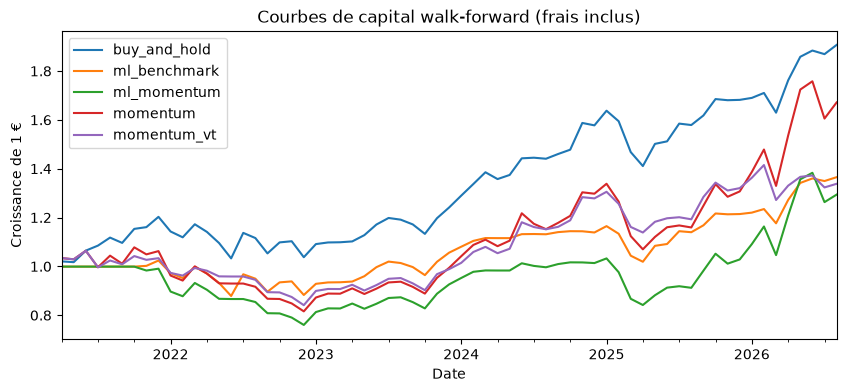

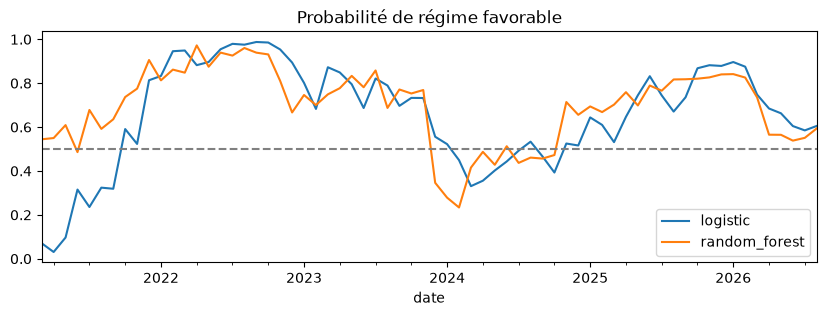

{'signal_date': '2026-08-31',
 'probability_logistic': 0.6051017432674574,
 'probability_random_forest': 0.5937575205617738,
 'exposure_logistic': 1.0}

In [5]:
import matplotlib.pyplot as plt

equity = pd.DataFrame({k: (1 + v).cumprod() for k, v in financial['returns'].items()})
ax = equity.plot(figsize=(10, 4), title='Courbes de capital walk-forward (frais inclus)')
ax.set_ylabel('Croissance de 1 €')
plt.show()
ax = study['probabilities'][['logistic', 'random_forest']].plot(figsize=(10, 3), title='Probabilité de régime favorable')
ax.axhline(0.5, color='grey', linestyle='--')
plt.show()
walk_forward['current']

In [6]:
report_path = PROJECT_ROOT / 'reports' / 'market_regime_report.md'
generate_regime_report(evaluation, study['backtest'], report_path, walk_forward)
print(f'Rapport généré : {report_path}')

Rapport généré : C:\Users\degar\OneDrive - De Vinci Higher Education (DVHE)\Perso\Projet Investissement\personal-quant-lab\reports\market_regime_report.md


## Limites

- Nombre d'observations faible (~130 mois) : risque de surapprentissage.
- Stationnarité non garantie des régimes de marché.
- Features uniquement issues des prix du benchmark (aucune donnée macro).
- Paliers d'exposition fixés a priori (guide), non optimisés.
- Les résultats passés ne préjugent pas des résultats futurs.
- Ce module est expérimental et ne doit pas déclencher d'ordres réels.